# Advanced models: gradient boosting and a tabular foundation model

Week 7. Can a stronger model beat the current best, **Random Forest + school districts + comparable sales** (`05e_comparable_sales.ipynb`)?

- **Gradient boosting:** LightGBM and XGBoost (required), plus CatBoost.
- **A pretrained tabular foundation model:** NVIDIA's [Kumo Tabular](https://huggingface.co/blog/nvidia/kumo-tabular). It isn't trained on our data at all. It reads a sample of training rows as examples ("context") and predicts new rows from them in one forward pass.
- **A simple ensemble:** the average of the best boosted model and the forest.

Every model gets the same inputs: the current best feature set, preprocessed by `da.make_preprocessor` (imputation and target encoding fit on each training window), with X = 18 months of training data.

**Months used.** To keep the run short, this notebook uses single months instead of the 6-month rolling backtest. Light tuning (depth, learning rate, number of trees) is scored on 2025-09. The tuned models are then compared on 2026-03, the last validation month, which played no part in tuning, so the comparison isn't biased toward the tuned models. One month is noisier than six: in earlier notebooks R² moved by about ±0.005 from month to month, so differences smaller than that are not conclusive. The test month, 2026-04, is held out and never scored.

In [1]:
# The boosting libraries must be imported before torch: torch loads its own OpenMP runtime,
# and LightGBM/XGBoost fits crash the kernel if torch's copy is loaded first.
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import torch
from scipy.stats import loguniform
from sdm.models.kumo.tabular.model import KumoTabular
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import RandomizedSearchCV

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science import features as ft
from idx_exchange_data_science.modeling import (
    backtest, build_model, fit_window, linear_baseline, median_ape_by, random_forest, score,
)
from idx_exchange_data_science.splits import MonthSplit, split, validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8e5bd0", "#52514e"]

X = 18
EVAL_MONTHS = validation_months("2026-04", n_months=1)  # 2026-03; 2026-04 is the held-out test month
TUNE_MONTHS = validation_months("2025-10", n_months=1)  # 2025-09, before every validation month
METRICS = ["r2", "mae", "mape", "median_ape", "within_10pct"]
RESULTS_DIR = Path("../results")
NUMERIC = ft.DISTRICT_NUMERIC_COLS + ft.COMP_COLS
CATEGORICAL = ft.DISTRICT_COLS

df = ft.build_table()
print("tuning months:", [str(m) for m in TUNE_MONTHS], "| validation months:", [str(m) for m in EVAL_MONTHS])

/Users/rohankrishnan/Documents/GitHub/IDX-Exchange-Data-Science/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


tuning months: ['2025-09'] | validation months: ['2026-03']


## 1. Light tuning of the boosted models
A random search over each model's main settings, scored by R² on the tuning month (`MonthSplit` works as a regular sklearn `cv=`). The number of trees is searched together with the learning rate, since the two trade off: a lower rate needs more trees.

| Model | Searched |
|---|---|
| LightGBM | trees, learning rate, leaves per tree, max depth, min rows per leaf, row and column subsampling |
| XGBoost | trees, learning rate, max depth, min child weight, row and column subsampling |
| CatBoost | trees, learning rate, depth, L2 regularization |

LightGBM with many leaves is by far the slowest (about a minute per fit at 255 leaves and 1,500 trees), so its search is capped at 127 leaves and 1,000 trees, with 15 draws. CatBoost gets 10.

In [2]:
def with_features(estimator):
    """The estimator after the current best feature set's preprocessing."""
    return build_model(estimator, da.make_preprocessor(NUMERIC, CATEGORICAL))


SEARCHES = {
    "LightGBM": (with_features(LGBMRegressor(subsample_freq=1, n_jobs=-1, random_state=0, verbose=-1)), 15, {
        "lgbmregressor__n_estimators": [300, 600, 1000],
        "lgbmregressor__learning_rate": loguniform(0.02, 0.2),
        "lgbmregressor__num_leaves": [31, 63, 127],
        "lgbmregressor__max_depth": [-1, 8, 12],
        "lgbmregressor__min_child_samples": [10, 20, 50, 100],
        "lgbmregressor__subsample": [0.7, 0.85, 1.0],
        "lgbmregressor__colsample_bytree": [0.5, 0.7, 1.0],
    }),
    "XGBoost": (with_features(XGBRegressor(tree_method="hist", n_jobs=-1, random_state=0)), 20, {
        "xgbregressor__n_estimators": [300, 600, 1000, 1500],
        "xgbregressor__learning_rate": loguniform(0.02, 0.2),
        "xgbregressor__max_depth": [4, 6, 8, 10],
        "xgbregressor__min_child_weight": [1, 5, 20],
        "xgbregressor__subsample": [0.7, 0.85, 1.0],
        "xgbregressor__colsample_bytree": [0.5, 0.7, 1.0],
    }),
    "CatBoost": (with_features(CatBoostRegressor(thread_count=-1, random_seed=0, verbose=0)), 10, {
        "catboostregressor__iterations": [500, 1000, 1500],
        "catboostregressor__learning_rate": loguniform(0.03, 0.2),
        "catboostregressor__depth": [4, 6, 8],
        "catboostregressor__l2_leaf_reg": [1, 3, 10],
    }),
}

tuned, tuning = {}, []
for name, (model, n_iter, space) in SEARCHES.items():
    start = time.perf_counter()
    search = RandomizedSearchCV(model, space, n_iter=n_iter, cv=MonthSplit(TUNE_MONTHS, X), scoring="r2",
                                refit=False, random_state=0)
    search.fit(df, df[da.TARGET])
    tuned[name] = model.set_params(**search.best_params_)
    results = pd.DataFrame(search.cv_results_)
    tuning.append(results.assign(model=name)[["model", "params", "mean_test_score", "mean_fit_time"]])
    print(f"{name}: best tuning R² {search.best_score_:.4f} ({time.perf_counter() - start:.0f}s, "
          f"{results['mean_fit_time'].mean():.0f}s per fit)")
tuning = pd.concat(tuning, ignore_index=True).rename(columns={"mean_test_score": "tuning_r2"})

LightGBM: best tuning R² 0.9096 (81s, 5s per fit)


XGBoost: best tuning R² 0.9104 (139s, 7s per fit)


CatBoost: best tuning R² 0.9112 (85s, 8s per fit)


In [3]:
best_params = pd.DataFrame({
    name: {key.split("__")[1]: value for key, value in params.items()}
    for name, params in tuning.loc[tuning.groupby("model")["tuning_r2"].idxmax()].set_index("model")["params"].items()
}).T
best_params.insert(0, "tuning R²", tuning.groupby("model")["tuning_r2"].max())
best_params

,tuning R²,depth,iterations,l2_leaf_reg,learning_rate,colsample_bytree,max_depth,min_child_samples,n_estimators,num_leaves,subsample,min_child_weight
CatBoost,0.9112,8.0000,"1,500.0000",1.0000,0.0882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LightGBM,0.9096,NaN,NaN,NaN,0.0821,1.0000,8.0000,20.0000,600.0000,63.0000,1.0000,NaN
XGBoost,0.9104,NaN,NaN,NaN,0.0920,0.5000,8.0000,NaN,600.0000,NaN,1.0000,1.0000


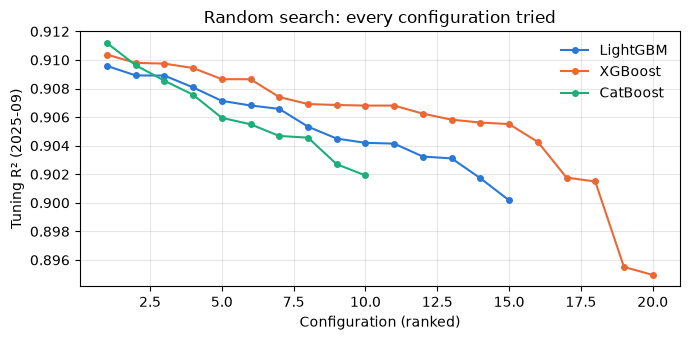

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for color, (name, group) in zip(COLORS, tuning.groupby("model", sort=False)):
    ranked = group["tuning_r2"].sort_values(ascending=False).to_numpy()
    ax.plot(range(1, len(ranked) + 1), ranked, marker="o", markersize=4, linewidth=1.5, color=color, label=name)
ax.set(xlabel="Configuration (ranked)", ylabel="Tuning R² (2025-09)", title="Random search: every configuration tried")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()

**Observations**
- **The three boosted models tune to almost the same score** on 2025-09: R² 0.910 (LightGBM), 0.910 (XGBoost) and 0.911 (CatBoost). The 0.0016 spread is well within month-to-month noise.
- **LightGBM and XGBoost settled in the middle of their ranges:** 63 leaves / depth 8 / 600 trees for LightGBM, depth 8 / 600 trees for XGBoost, both with a learning rate near 0.08–0.09.
- **CatBoost picked the edge of its range** (depth 8 and 1,500 trees, both the largest allowed), so a wider search might still improve it.

## 2. Kumo Tabular
Kumo Tabular (small, 28M parameters) was pretrained only on synthetic tables, so nothing from this data went into its weights. It runs on the Mac's GPU (MPS).

- **Context:** its input is a sample of labeled rows. The training window has about 190K rows, more than the model was built for (up to 60K), so it gets a random 30K rows from the same 18 months the other models train on. Only training rows are used, so the same leakage rules hold.
- **Inputs:** the same preprocessed features as the boosted models, with living area and lot size logged and every column standardized. It takes numbers only, which the target encoding already provides. Raw lot sizes go up to 2.5×10¹⁰ sq ft, and with unscaled inputs predictions stalled.
- **Target:** log price. It predicts 999 quantiles of each home's log price. The point prediction is the mean of those quantiles converted to dollars, an estimate of the expected price.

The wrapper below makes it an sklearn regressor, so it runs through the same `backtest` as everything else. It predicts 500 homes at a time: batches of 2,000 stalled on the Mac's GPU.

In [5]:
class KumoTabularRegressor(RegressorMixin, BaseEstimator):
    """NVIDIA Kumo Tabular as an sklearn regressor. fit() only stores `context_rows` random training rows."""

    def __init__(self, context_rows=30_000, size="small", device="mps", random_state=0):
        self.context_rows = context_rows
        self.size = size
        self.device = device
        self.random_state = random_state

    def fit(self, X, y):
        rows = np.random.default_rng(self.random_state).permutation(len(X))[:self.context_rows]
        features = torch.tensor(np.asarray(X, dtype="float32")[rows], device=self.device)
        log_price = torch.tensor(np.log1p(np.asarray(y, dtype="float64"))[rows, None], dtype=torch.float32, device=self.device)
        self.model_ = KumoTabular(task="regression", size=self.size, device=self.device)
        self.model_.fit(features, log_price)
        return self

    def predict_quantiles(self, X, batch_size=500):
        """Each row's 999 predicted quantiles of price, in dollars."""
        features = np.asarray(X, dtype="float32")
        batches = [self.model_.predict(torch.tensor(features[i:i + batch_size], device=self.device)).numerical.cpu().numpy()
                   for i in range(0, len(features), batch_size)]
        return np.expm1(np.concatenate(batches).astype("float64"))

    def predict(self, X):
        return self.predict_quantiles(X).mean(axis=1)


kumo = build_model(KumoTabularRegressor(), da.make_preprocessor(NUMERIC, CATEGORICAL, log_features=True), scale=True)

## 3. Validation
Every candidate is trained on the 18 months before 2026-03 and scored on 2026-03. The reference is the current best, the random forest. The ensemble averages the predictions of the best boosted model (by tuning R²) and the forest, so it needs no extra fitting.

In [6]:
models = {
    "Baseline (LR)": linear_baseline(NUMERIC, CATEGORICAL),
    "Random Forest (current best)": with_features(random_forest()),
    **tuned,
    "Kumo Tabular": kumo,
}
start = time.perf_counter()
scores, predictions = backtest(models, df, EVAL_MONTHS, X)
print(f"backtest: {time.perf_counter() - start:.0f}s")

best_boosted = best_params["tuning R²"].idxmax()
ensemble = f"Average of {best_boosted} and Random Forest"
predictions[ensemble] = predictions[[best_boosted, "Random Forest (current best)"]].mean(axis=1)
evaluated = df.loc[predictions.index]
month = evaluated[da.DATE_COL].dt.to_period("M").astype(str)
ensemble_scores = [{"model": ensemble, "month": m, **score(group[da.TARGET], predictions.loc[group.index, ensemble])}
                   for m, group in evaluated.groupby(month)]
scores = pd.concat([scores, pd.DataFrame(ensemble_scores)], ignore_index=True)

validation = scores.set_index("model")[METRICS].loc[[*models, ensemble]]
validation["r2_vs_forest"] = validation["r2"] - validation.loc["Random Forest (current best)", "r2"]
validation["mae_vs_forest"] = validation["mae"] - validation.loc["Random Forest (current best)", "mae"]
validation

backtest: 95s


,r2,mae,mape,median_ape,within_10pct,r2_vs_forest,mae_vs_forest
model,,,,,,,
Baseline (LR),0.8502,"176,957.3437",0.1338,0.0984,0.5056,-0.0565,"29,786.6323"
Random Forest (current best),0.9067,"147,170.7114",0.1139,0.0769,0.6040,0.0000,0.0000
LightGBM,0.9104,"145,727.8714",0.1142,0.0794,0.5941,0.0037,"-1,442.8400"
XGBoost,0.9144,"142,383.1184",0.1113,0.0758,0.6118,0.0077,"-4,787.5930"
CatBoost,0.9112,"144,657.5937",0.1130,0.0785,0.5987,0.0044,"-2,513.1178"
Kumo Tabular,0.9080,"142,388.3438",0.1069,0.0721,0.6273,0.0012,"-4,782.3676"
Average of CatBoost and Random Forest,0.9126,"142,876.2394",0.1110,0.0762,0.6150,0.0059,"-4,294.4720"


**Observations**
- **All three boosted models beat the forest on 2026-03.** XGBoost gains the most: R² 0.914 vs 0.907 (+0.008) and MAE \$142.4K vs \$147.2K. CatBoost (+0.004) and LightGBM (+0.004) gain less. Only XGBoost's gain is clearly larger than the usual month-to-month noise (about ±0.005), and it is still a single month.
- **Kumo Tabular matches the forest in R² (0.908) and has the best percentage errors:** median 7.2% vs 7.7% for the forest, mean 10.7% vs 11.4%, and 62.7% of homes within 10% vs 60.4%. Its MAE ties XGBoost's (\$142.4K). It was never trained on this data and saw only 30K of the 189K training rows.
- **The ensemble (CatBoost + forest) lands in between** (0.913). CatBoost was picked for it because it had the best tuning R². Swapping in XGBoost now would use the validation month to make that choice.

### Error by price decile
Median absolute percentage error on 2026-03, for the forest, the best boosted model, Kumo Tabular and the ensemble. All are scored on the same rows.

In [7]:
reference = "Random Forest (current best)"
finalists = [reference, best_boosted, "Kumo Tabular", ensemble]
errors = median_ape_by(predictions[finalists], evaluated[da.TARGET], pd.qcut(evaluated[da.TARGET], 10))
errors.index = [f"{b.right / 1e6:.2f}M" for b in errors.index]
errors.rename_axis("price decile (upper edge)").round(2)

,Random Forest (current best),CatBoost,Kumo Tabular,Average of CatBoost and Random Forest
price decile (upper edge),,,,
0.45M,8.4100,9.0700,7.4300,8.3000
0.57M,6.4800,6.6500,6.0200,6.3300
0.68M,5.3200,5.9500,5.2500,5.3700
0.78M,5.9700,6.2700,5.6700,6.0300
0.89M,6.0700,6.2200,5.6300,6.0300
1.06M,7.3000,7.5500,6.5100,7.2300
1.30M,8.2700,8.6500,8.1400,8.4100
1.61M,9.3100,8.9400,8.2300,8.8600
2.28M,10.1000,9.5700,10.0300,9.8500


### Kumo Tabular's price ranges
Kumo Tabular predicts a full distribution, not just a number. If its 10%–90% range is well calibrated, about 80% of homes should sell inside it.

In [8]:
month_fit = fit_window(kumo, df, EVAL_MONTHS[-1], X)
_, last_month = split(df, EVAL_MONTHS[-1], X)
quantiles = month_fit[-1].predict_quantiles(month_fit[:-1].transform(last_month))
actual = last_month[da.TARGET].to_numpy()
coverage = pd.Series({
    f"{low}%–{high}% range": ((actual >= quantiles[:, low * 10 - 1]) & (actual <= quantiles[:, high * 10 - 1])).mean()
    for low, high in [(25, 75), (10, 90), (5, 95)]
})
width = np.median((quantiles[:, 899] - quantiles[:, 99]) / actual)
print(f"{EVAL_MONTHS[-1]}: median width of the 10%–90% range = {width:.0%} of the price")
coverage.to_frame("share of homes inside (should be 50% / 80% / 90%)")

2026-03: median width of the 10%–90% range = 28% of the price


,share of homes inside (should be 50% / 80% / 90%)
25%–75% range,0.4813
10%–90% range,0.7834
5%–95% range,0.8915


**Observations**
- **Kumo Tabular has the lowest error in 8 of 10 price deciles,** with the largest gains on the cheapest homes (7.4% vs 8.4% for the forest) and in the middle of the market. It is weakest on the most expensive homes (12.2% vs 11.8%).
- **CatBoost beats the forest only in the top three deciles,** where dollar errors are largest. That matches its R² gain coming from expensive homes.
- **Kumo Tabular's price ranges are well calibrated:** 78% of homes sold inside its 10%–90% range (target 80%), 48% inside the 25%–75% range (target 50%), and 89% inside the 5%–95% range (target 90%). The 10%–90% range is typically 28% of the price wide, about \$240K for an \$850K home. None of the other models give a range at all.

## 4. What the best boosted model learned (SHAP)
SHAP splits each prediction into one contribution per feature, in dollars, so that the contributions add up to the prediction. `TreeExplainer` computes them exactly for tree models. The model is fit on the 18 months before 2026-03 and explains 2,000 random 2026-03 homes.

In [9]:
boosted_fit = fit_window(tuned[best_boosted], df, EVAL_MONTHS[-1], X)
sample = last_month.sample(2000, random_state=0)
features = boosted_fit[:-1].transform(sample)
explanation = shap.TreeExplainer(boosted_fit[-1])(features)

mean_abs = pd.Series(np.abs(explanation.values).mean(axis=0), index=features.columns).sort_values(ascending=False)
mean_abs.head(12).to_frame("mean |SHAP| ($)").style.format("${:,.0f}")

,mean |SHAP| ($)
LogCompImpliedPrice,"$225,963"
PostalCode,"$175,029"
Latitude,"$140,948"
Longitude,"$140,517"
City,"$93,325"
BathroomsTotalInteger,"$73,518"
LotSizeSquareFeet,"$65,999"
PropertyAge,"$33,970"
LivingArea,"$29,835"
ElementaryDistrict,"$23,698"


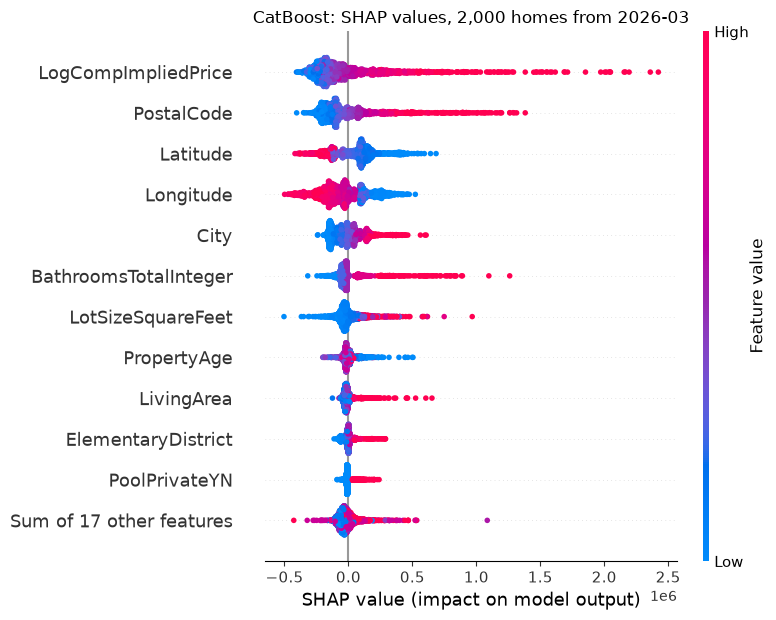

In [10]:
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title(f"{best_boosted}: SHAP values, 2,000 homes from {EVAL_MONTHS[-1]}")
plt.tight_layout()

In [11]:
# one home: how the model gets from the average prediction to this home's price
home = int(np.argmax(sample[da.TARGET].to_numpy() > sample[da.TARGET].quantile(0.9)))
print(f"actual ${sample[da.TARGET].iloc[home]:,.0f}, predicted ${boosted_fit.predict(sample.iloc[[home]])[0]:,.0f}")
shap.plots.waterfall(explanation[home], max_display=10, show=False)
plt.tight_layout()

actual $2,470,000, predicted $2,322,516


**Observations**
- **Comparable sales and location drive the predictions.** The comparable-implied price moves a typical prediction by \$226K, then the ZIP encoding (\$175K), latitude and longitude (about \$141K each) and the city encoding (\$93K).
- **Living area looks unimportant (\$30K) only because it is already inside `LogCompImpliedPrice`,** which is the neighbours' price per square foot times the home's living area.
- **After location, bathrooms (\$74K) and lot size (\$66K) matter most.** The school district columns contribute little on top of ZIP and city (\$24K for the elementary district).
- **The waterfall plot shows a single home:** it starts at the average prediction and adds each feature's contribution until it reaches this home's \$2.32M estimate (it sold for \$2.47M).

## Summary
2026-03, X = 18, current best feature set:

| Model | R² | MAE | Mean % error | Median % error | Within 10% |
|---|---|---|---|---|---|
| Baseline (LR) | 0.850 | \$177.0K | 13.4% | 9.8% | 50.6% |
| Random Forest (current best) | 0.907 | \$147.2K | 11.4% | 7.7% | 60.4% |
| LightGBM | 0.910 | \$145.7K | 11.4% | 7.9% | 59.4% |
| **XGBoost** | **0.914** | **\$142.4K** | 11.1% | 7.6% | 61.2% |
| CatBoost | 0.911 | \$144.7K | 11.3% | 7.9% | 59.9% |
| Kumo Tabular | 0.908 | **\$142.4K** | **10.7%** | **7.2%** | **62.7%** |
| CatBoost + forest average | 0.913 | \$142.9K | 11.1% | 7.6% | 61.5% |

- **XGBoost is the strongest model in R² and dollars,** and it trains in about a second instead of the forest's 18. One month is not enough to replace the forest outright: the gain (+0.008) is only just above month-to-month noise. Since XGBoost is fast, confirming it on the full 6-month backtest is cheap.
- **Kumo Tabular is the most accurate for a typical home** (lowest median and mean % error), with no training, and it gives calibrated price ranges. It is the only model here that does both.
- **The two are good at different things:** XGBoost on expensive homes, where R² and dollars are decided, and Kumo Tabular on typical homes. Averaging them is the obvious next experiment.
- The test month (2026-04) was not scored, per the project protocol. All numbers are from the 2026-03 validation month.

In [12]:
validation.reset_index().to_csv(RESULTS_DIR / "advanced_models_comparison.csv", index=False)
scores.to_csv(RESULTS_DIR / "advanced_models_backtest.csv", index=False)
tuning.assign(params=tuning["params"].astype(str)).to_csv(RESULTS_DIR / "advanced_models_tuning.csv", index=False)